In [1]:
import torch
import numpy as np
import os
from pathlib import Path
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
from data_processing.utils import SeamlessSMPLHLoader
from pprint import pprint
from dataclasses import asdict
import json
import cv2
import matplotlib.pyplot as plt

In [2]:
# npz_path = os.path.expanduser('~/thesis/MPI_Project/data/seamless/downloads/observation/naturalistic/train/0038/0039/V01_S0207_I00000140_P1386.npz')
npz_path = os.path.expanduser('~/thesis/MPI_Project/data/seamless/downloads/observation/naturalistic/train/0031/0042/V00_S1929_I00000221_P0775.npz')
# npz_path = os.path.expanduser('~/thesis/MPI_Project/data/seamless/downloads/observation/naturalistic/train/0033/0001/V01_S0037_I00000307_P1071.npz')

In [3]:
loader = SeamlessSMPLHLoader(npz_path, with_meta_data=True, load_vertices=False)

In [4]:
# data_dict = asdict(loader.meta_data)
# pprint(data_dict)

In [5]:
print(f"Body shape: {loader.SMPLParams.body.shape}") # should be (frames, 21 or 22, 3)
print(f"Left hand shape: {loader.SMPLParams.left_hand.shape}") # should be (frames, 15, 3)
print(f"Right hand shape: {loader.SMPLParams.right_hand.shape}") # should be (frames, 15, 3)

Body shape: torch.Size([6420, 21, 3])
Left hand shape: torch.Size([6420, 15, 3])
Right hand shape: torch.Size([6420, 15, 3])


In [6]:
print(loader.get_trainable_pose().shape)

torch.Size([6420, 129])


In [7]:
print(loader.meta_data.keypoints.shape)
print(loader.meta_data.transcript.get('metadata:vad'))

(6420, 133, 3)
[{'start': 1.8099999999999454, 'end': 2.318000000000211}, {'start': 12.914000000000215, 'end': 13.230000000000018}, {'start': 15.25, 'end': 15.661999999999807}, {'start': 27.697999999999865, 'end': 28.302000000000135}, {'start': 63.73000000000002, 'end': 64.846}, {'start': 66.86599999999999, 'end': 67.98199999999997}, {'start': 80.49800000000005, 'end': 81.07000000000016}, {'start': 82.22600000000011, 'end': 82.54199999999992}, {'start': 90.25799999999981, 'end': 90.92599999999993}, {'start': 101.55400000000009, 'end': 102.2539999999999}, {'start': 118.51400000000012, 'end': 118.95800000000008}, {'start': 119.82600000000002, 'end': 120.39800000000014}, {'start': 124.72200000000021, 'end': 126.47800000000007}, {'start': 134.92999999999984, 'end': 139.91800000000012}, {'start': 141.52199999999993, 'end': 142.51000000000022}, {'start': 142.73799999999983, 'end': 143.21399999999994}, {'start': 145.04199999999992, 'end': 146.0300000000002}, {'start': 146.54599999999982, 'end'

In [8]:
data = np.load(npz_path, allow_pickle=True)
print(list(data.keys()))
#print(data.get('movement:emotion_scores').shape)
print(data.get('metadata:vad'))
# print(data.get('movement_v4:emotion_scores').shape)

['boxes_and_keypoints:box', 'boxes_and_keypoints:is_valid_box', 'boxes_and_keypoints:keypoints', 'movement:EmotionArousalToken', 'movement:EmotionValenceToken', 'movement:FAUToken', 'movement:FAUValue', 'movement:alignment_head_rotation', 'movement:alignment_translation', 'movement:emotion_arousal', 'movement:emotion_scores', 'movement:emotion_valence', 'movement:expression', 'movement:frame_latent', 'movement:gaze_encodings', 'movement:head_encodings', 'movement:hypernet_features', 'movement:is_valid', 'movement_v4:EmotionArousalToken', 'movement_v4:EmotionValenceToken', 'movement_v4:FAUToken', 'movement_v4:FAUValue', 'movement_v4:alignment_head_rotation', 'movement_v4:alignment_translation', 'movement_v4:emotion_arousal', 'movement_v4:emotion_scores', 'movement_v4:emotion_valence', 'movement_v4:expression', 'movement_v4:frame_latent', 'movement_v4:gaze_encodings', 'movement_v4:head_encodings', 'movement_v4:hypernet_features', 'movement_v4:is_occluded', 'movement_v4:is_valid', 'smplh:

In [9]:
# json_path = Path(npz_path).with_suffix('.json')
# if json_path.exists():
#     with open(json_path, 'r') as file:
#         transcript = json.load(file)

# annotation_keys = [key for key in transcript.keys() if "annotations:" in key]
# for key in annotation_keys:
#     data = transcript[key]
#     events = data if isinstance(data, list) else [data]
#     for event in events:
#         if isinstance(data, dict) and 'start_ts' in data:
#             s_f = int(event['start_ts'] * 30)
#             print(s_f)

In [10]:
print(data.get("smplh:body_pose").shape)
print(data.get("smplh:global_orient").shape)
print(list(data.keys()))

(6420, 21, 3)
(6420, 3)
['boxes_and_keypoints:box', 'boxes_and_keypoints:is_valid_box', 'boxes_and_keypoints:keypoints', 'movement:EmotionArousalToken', 'movement:EmotionValenceToken', 'movement:FAUToken', 'movement:FAUValue', 'movement:alignment_head_rotation', 'movement:alignment_translation', 'movement:emotion_arousal', 'movement:emotion_scores', 'movement:emotion_valence', 'movement:expression', 'movement:frame_latent', 'movement:gaze_encodings', 'movement:head_encodings', 'movement:hypernet_features', 'movement:is_valid', 'movement_v4:EmotionArousalToken', 'movement_v4:EmotionValenceToken', 'movement_v4:FAUToken', 'movement_v4:FAUValue', 'movement_v4:alignment_head_rotation', 'movement_v4:alignment_translation', 'movement_v4:emotion_arousal', 'movement_v4:emotion_scores', 'movement_v4:emotion_valence', 'movement_v4:expression', 'movement_v4:frame_latent', 'movement_v4:gaze_encodings', 'movement_v4:head_encodings', 'movement_v4:hypernet_features', 'movement_v4:is_occluded', 'moveme

# Detect the boundaries of the recording
Conclusion, it is not 100% accuracte but can definitely be used for a sped-up out of screen hand motion detection. Since loading the video implies downloading it, and with this method we can get away without downloading it.

In [11]:
def infer_dimensions_from_boxes(loader):
    """
    The idea is the see if the boxes_and_keypoints:box data from seamless can be used to detect the recording video size
    """
    boxes = loader.data.get('boxes_and_keypoints:box')
    
    if boxes is not None:
        max_x = np.max(boxes[:, [0, 2]])
        max_y = np.max(boxes[:, [1, 3]])
        return max_x, max_y
    return None, None

print(infer_dimensions_from_boxes(loader))
video_capture = cv2.VideoCapture(loader.meta_data.video_file)

# Get frame dimensions from the actual video
frame_width = int(video_capture.get(cv2.CAP_PROP_FRAME_WIDTH))
frame_height = int(video_capture.get(cv2.CAP_PROP_FRAME_HEIGHT))
video_capture.release()
print(frame_width, frame_height)

(1080.0, 1799.42)
1080 1920


### Quick comparison, to see if the method where we use the video compared to only using the bounding box is accurate

Conclusion: Yes I would say so, in multiple examples it was 100% accurate and i have yet to see on where it was not. It also often only is around 120-400 frames implying it does not happen for more than 5 seconds for an entire video meaning some inaccuracy would be fine if it does occur

In [12]:
def compare_visibility_methods(loader, visibility_threshold=0.5):
    """
    Compares the bounding box method against the video boundary method
    """
    # video based method
    cap = cv2.VideoCapture(str(loader.meta_data.video_file))
    v_width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    v_height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    cap.release()

    # bounding box method
    boxes = loader.data.get('boxes_and_keypoints:box')
    limit_x = np.max(boxes[:, [0, 2]])
    limit_y = np.max(boxes[:, [1, 3]])

    # keypoints for hands
    hand_pts = loader.meta_data.keypoints[:, 91:133, :2]

    # video vs bounding box
    def get_mask(w, h):
        off = (hand_pts[..., 0] <= 0) | (hand_pts[..., 0] >= w) | (hand_pts[..., 1] <= 0) | (hand_pts[..., 1] >= h)
        return np.mean(off, axis=1) <= visibility_threshold

    video_mask = get_mask(v_width, v_height)
    box_mask = get_mask(limit_x, limit_y)

    # align them
    video_off_indices = set(np.where(~video_mask)[0])
    box_off_indices = set(np.where(~box_mask)[0])
    matches = video_off_indices.intersection(box_off_indices)

    print(f"--- Comparison for {loader.sample_name} ---")
    print(f"Video Res: {v_width}x{v_height} | Box Limit: {limit_x:.1f}x{limit_y:.1f}")
    print(f"Frames Off-Screen (Video): {len(video_off_indices)}")
    print(f"Frames Off-Screen (Box):   {len(box_off_indices)}")
    print(f"Direct Match (Overlap):    {len(matches)}")
    
    if len(video_off_indices) > 0:
        accuracy = (len(matches) / len(video_off_indices)) * 100
        print(f"Method Alignment: {accuracy:.2f}%")

print(compare_visibility_methods(loader))

--- Comparison for V00_S1929_I00000221_P0775 ---
Video Res: 1080x1920 | Box Limit: 1080.0x1799.4
Frames Off-Screen (Video): 11
Frames Off-Screen (Box):   11
Direct Match (Overlap):    11
Method Alignment: 100.00%
None


In [13]:
print(np.sum(loader.meta_data.hand_offscreen))
print(f"The percentage of off screen frames for this interaction is {(np.sum(loader.meta_data.hand_offscreen) / loader.num_frames) * 100} percent")

139
The percentage of off screen frames for this interaction is 2.165109034267913 percent


In [14]:
left_high_offscreen_values = loader.meta_data.left_hand_offscreen_percentage[loader.meta_data.left_hand_offscreen_percentage > 0.5]
right_high_offscreen_values = loader.meta_data.right_hand_offscreen_percentage[loader.meta_data.right_hand_offscreen_percentage > 0.5]

both_hands_off = (loader.meta_data.left_hand_offscreen_percentage > 0.5) & (loader.meta_data.right_hand_offscreen_percentage > 0.5)

print(f"Total lefthand frames > 50% off-screen: {len(left_high_offscreen_values)}")
print(f"Total right hand frames > 50% off-screen: {len(right_high_offscreen_values)}")
print(f"Frames where both hands are > 50% off: {np.sum(both_hands_off)}")

Total lefthand frames > 50% off-screen: 79
Total right hand frames > 50% off-screen: 22
Frames where both hands are > 50% off: 9


### Check if we can detect if a hand moves out of frame accurately
The conclusion is yes, but we need to use the width and height of the recording and see if keypoints fall outside. Additionally i tried using the confidence scores but these are not trustworthy

In [ ]:
video_capture = cv2.VideoCapture(loader.meta_data.video_file)

# get frame dimensions for the boundary check
frame_width = int(video_capture.get(cv2.CAP_PROP_FRAME_WIDTH))
frame_height = int(video_capture.get(cv2.CAP_PROP_FRAME_HEIGHT))

start_frame_index = 1350
video_capture.set(cv2.CAP_PROP_POS_FRAMES, start_frame_index)

KEYPOINT_MAPPING = {
    "body_points":  {"index_range": range(0, 17),    "color_bgr": (255, 204, 0)},
    "feet_points":  {"index_range": range(17, 23),   "color_bgr": (0, 140, 255)},
    "face_points":  {"index_range": range(23, 91),   "color_bgr": (220, 220, 220)},
    "left_hand":    {"index_range": range(91, 112),  "color_bgr": (130, 238, 24)},
    "right_hand":   {"index_range": range(112, 133), "color_bgr": (10, 10, 230)}
}

GOOD_CONFIDENCE_THRESHOLD = 0.45
total_display_frames = 60
columns_count = 3
rows_count = (total_display_frames + columns_count - 1) // columns_count

figure, axis_array = plt.subplots(
    rows_count, 
    columns_count, 
    figsize=(20, rows_count * 12), 
    layout="constrained"
)
axis_flat_list = axis_array.flatten()

keypoint_data = loader.meta_data.keypoints

for display_counter in range(total_display_frames):
    off_screen_confidences = []
    on_screen_confidences = []
    success, current_frame = video_capture.read()
    if not success: 
        break
    
    actual_data_index = start_frame_index + display_counter
    current_frame_keypoints = keypoint_data[actual_data_index]
    
    # hand off-screen detection
    is_hand_offscreen = False
    
    for body_part_name, part_info in KEYPOINT_MAPPING.items():
        point_color_bgr = part_info["color_bgr"]
        
        for point_index in part_info["index_range"]:
            pos_x, pos_y, confidence_score = current_frame_keypoints[point_index]
            
            # Check if point is outside frame boundaries
            is_outside = (pos_x < 0 or pos_x > frame_width or pos_y < 0 or pos_y > frame_height)
            if is_outside:
                off_screen_confidences.append(confidence_score)
            else:
                on_screen_confidences.append(confidence_score)
            
            if confidence_score > 0.0:
                # If this point is part of a hand and is outside, trip the flag
                if ("hand" in body_part_name) and is_outside:
                    is_hand_offscreen = True
                
                # Only draw if actually on screen to avoid OpenCV errors
                if not is_outside:
                    thickness = -1 if confidence_score >= GOOD_CONFIDENCE_THRESHOLD else 2
                    cv2.circle(current_frame, (int(pos_x), int(pos_y)), 6, point_color_bgr, thickness)
    
    frame_rgb_format = cv2.cvtColor(current_frame, cv2.COLOR_BGR2RGB)
    
    axis_flat_list[display_counter].imshow(frame_rgb_format, aspect='auto')

    # The title for each image
    status_text = "handoffscreen: true" if is_hand_offscreen else "handoffscreen: false"
    axis_flat_list[display_counter].set_title(
        f"Frame {actual_data_index} | {status_text}", 
        color='white', 
        backgroundcolor='black'
    )
    axis_flat_list[display_counter].axis('off')
    
    #- I used this to check the confidence scores to see if we could use those instead, conclusion was we could not
    # avg_off = np.mean(off_screen_confidences) if off_screen_confidences else 0
    # avg_on = np.mean(on_screen_confidences) if on_screen_confidences else 0
    # print(f"--- Frame {actual_data_index} Confidence Stats where handoffscreen = {is_hand_offscreen} ---")
    # print(f"Average Confidence (OFF-SCREEN): {avg_off:.4f}")
    # print(f"Average Confidence (ON-SCREEN):  {avg_on:.4f}")
    # print(f"Ratio (Off/On): {avg_off/avg_on if avg_on > 0 else 0:.4f}")

for empty_index in range(display_counter + 1, len(axis_flat_list)):
    axis_flat_list[empty_index].axis('off')

video_capture.release()
plt.show()

### Movement graph to see when and where there is movement

Conclusion there is correlation between the VAD and Movement, a person moves more when speaking. Additionally  we can use this movement value to segment better, and more high quality data

The idea for filtering only important VAD frames, would be to take the top 25% intensity values and see if a VAD frame sequence contains atleast 1 of these top 25% values. If that is the case we keep it

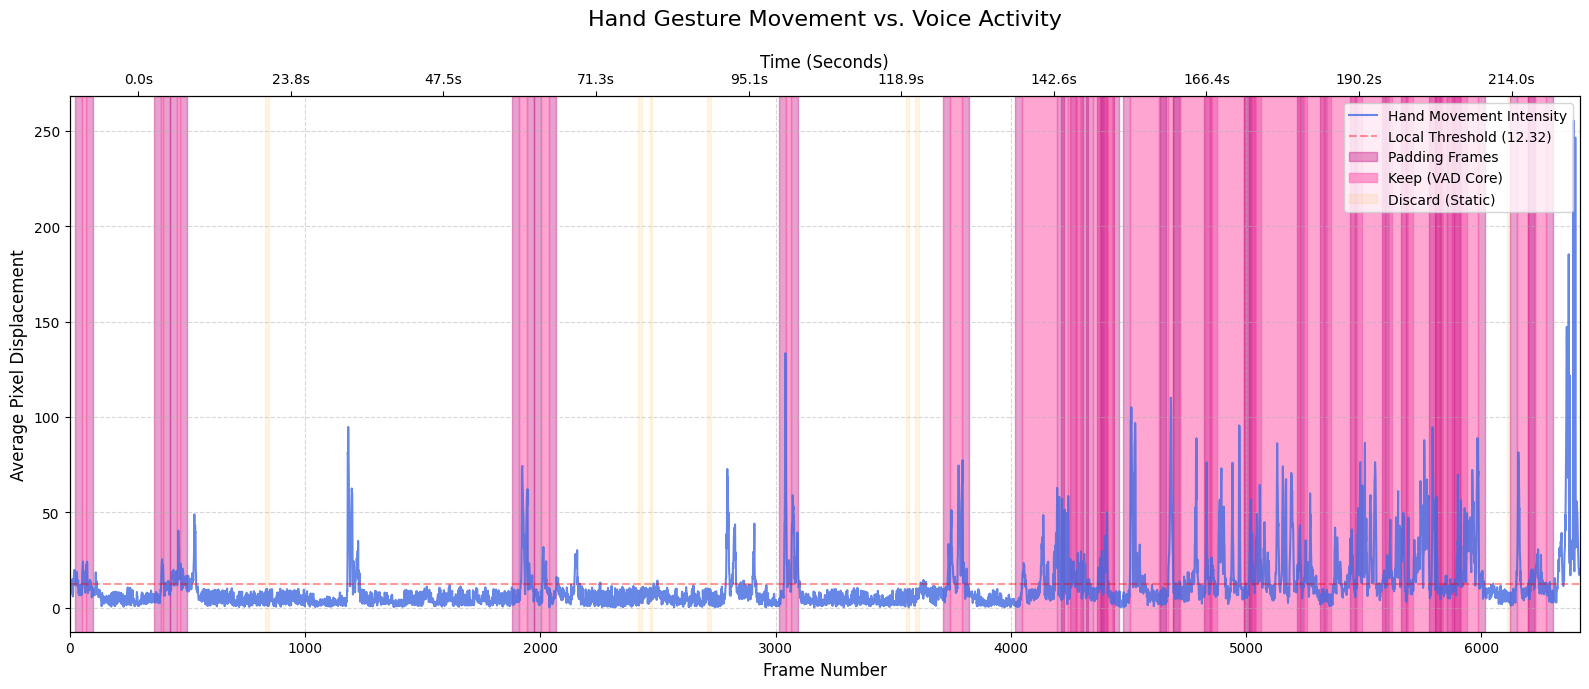

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Get video properties
video_capture = cv2.VideoCapture(loader.meta_data.video_file)
frames_per_second = video_capture.get(cv2.CAP_PROP_FPS)
video_capture.release()

hand_indices = range(91, 133)
all_keypoints = loader.meta_data.keypoints
hand_coordinates = all_keypoints[:, hand_indices, :2]

# calculate movement (temporal variance)
displacements = np.linalg.norm(hand_coordinates[1:] - hand_coordinates[:-1], axis=2)
movement_magnitude = np.mean(displacements, axis=1)

# calculate adaptive peak threshold (top 25% of movement)
local_threshold = np.percentile(movement_magnitude, 75)

# define temporal padding to capture movement before/after speech
padding_seconds = 1
padding_frames = int(padding_seconds * frames_per_second)

# Plotting
figure, axis_bottom = plt.subplots(figsize=(16, 7))
axis_bottom.plot(movement_magnitude, color='royalblue', linewidth=1.5, label='Hand Movement Intensity', alpha=0.8)

# visualize the local threshold line
axis_bottom.axhline(y=local_threshold, color='red', linestyle='--', alpha=0.4, label=f'Local Threshold ({local_threshold:.2f})')

# overlay with the VAD to see if there is a pattern
voice_activity_data = loader.meta_data.transcript['metadata:vad']

first_keep_flag = True
first_pad_flag = True
first_discard_flag = True

for segment in voice_activity_data:
    # Use start and end times directly from the VAD metadata
    start_time = segment['start']
    end_time = segment['end']
    
    # Convert seconds to frame indices
    start_frame = int(start_time * frames_per_second)
    end_frame = int(end_time * frames_per_second)
    
    # check for a local peak within this VAD block
    idx_start = max(0, start_frame)
    idx_end = min(len(movement_magnitude), end_frame)
    
    is_active = False
    if idx_start < idx_end:
        block_max = np.max(movement_magnitude[idx_start:idx_end])
        if block_max > local_threshold:
            is_active = True
            
    if is_active:
        # calculate padded boundaries
        padded_start = max(0, start_frame - padding_frames)
        padded_end = min(len(movement_magnitude), end_frame + padding_frames)
        
        # plot ONLY the leading padding (frames before VAD)
        if padded_start < start_frame:
            axis_bottom.axvspan(padded_start, start_frame, color='#C71585', alpha=0.4, 
                                label='Padding Frames' if first_pad_flag else "")
            first_pad_flag = False
            
        # plot ONLY the trailing padding (frames after VAD)
        if padded_end > end_frame:
            axis_bottom.axvspan(end_frame, padded_end, color='#C71585', alpha=0.4)
        
        # plot the original VAD core
        axis_bottom.axvspan(start_frame, end_frame, color='#FF69B4', alpha=0.6, 
                            label='Keep (VAD Core)' if first_keep_flag else "")
        first_keep_flag = False
    else:
        axis_bottom.axvspan(start_frame, end_frame, color='orange', alpha=0.1,
                            label='Discard (Static)' if first_discard_flag else "")
        first_discard_flag = False

# PLOTTING
axis_top = axis_bottom.twiny()

total_frames = len(movement_magnitude)
total_seconds = total_frames / frames_per_second
axis_top.set_xlim(axis_bottom.get_xlim())
axis_top.set_xticks(np.linspace(0, total_frames, 10))
axis_top.set_xticklabels([f"{s:.1f}s" for s in np.linspace(0, total_seconds, 10)])
axis_top.set_xlabel("Time (Seconds)", fontsize=12)

axis_bottom.set_title("Hand Gesture Movement vs. Voice Activity", fontsize=16, pad=20)
axis_bottom.set_xlabel("Frame Number", fontsize=12)
axis_bottom.set_ylabel("Average Pixel Displacement", fontsize=12)
axis_bottom.legend(loc='upper right')
axis_bottom.grid(True, linestyle='--', alpha=0.5)
axis_bottom.set_xlim(0, total_frames)

plt.tight_layout()
plt.show()